# Notebook 9 — SOLUTION

## Short version

**The manipulation suppresses firing by about 20%, and 32 of the 40 units go
down.** The paired t-test misses it completely (p = 0.63). This is a **power**
failure, not a Type I failure, and it comes from a mismatch between the shape of
the effect and the shape of the statistic:

1. **The effect is multiplicative.** Each unit's rate is scaled by a factor of
   about 0.8. That is what most neural manipulations do: gain changes, not
   additive offsets.
2. **Baseline rates are lognormal and very wide**, 0.11 to 82 spikes/s here.
3. So the **difference in spikes/s is proportional to the unit's rate**. The
   82 spikes/s unit moves by ~16 spikes/s; the 1 spikes/s unit moves by ~0.2. The
   mean paired difference is therefore a **rate-weighted average**, dominated by a
   handful of fast units, with an effective sample size of about **10 of 40**. Its
   standard deviation is inflated by exactly the same units.

The paired t-test is a perfectly good test of the mean difference in spikes/s. It
is just that on multiplicative data with lognormal rates, the mean difference in
spikes/s is a statistic with almost no power, because you have effectively
measured it in ten neurons rather than forty.

**The fix is simple.** Any of the following finds the effect immediately:

| test | p |
|---|---|
| paired t-test on rate differences | **0.63** |
| Wilcoxon signed-rank on the differences | **0.0006** |
| sign test (just count how many went down) | **0.0002** |
| paired t-test on **log** rates | **1.7e-06** |

Over repeated experiments from this generative model the paired t-test detects the
real effect **43%** of the time, Wilcoxon **94%**, and the log-scale t-test
**99%**.

**But do not read this as "always use Wilcoxon."** Evidence 5 shows that the
paired t-test, the Wilcoxon signed-rank test and the sign test have three
different null hypotheses, and each one misbehaves when its own null is violated.
Wilcoxon tests symmetry about zero, not the mean, and it rejects 42% of the time
in a case where the mean difference is exactly zero.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42

C_OFF, C_ON = '0.35', 'tab:purple'


In [2]:
d = np.load('data/data.npz')
counts_off = d['counts_off']            # (units,) spikes with the laser off
counts_on  = d['counts_on']             # (units,) spikes with the laser on
duration   = float(d['duration'])       # s spent in EACH condition

off = counts_off / duration             # spikes/s, one number per unit
on  = counts_on  / duration
n_units = off.size
print(f'{n_units} units, {duration/60:.0f} min per condition')
print(f'baseline rates: median {np.median(off):.2f}, '
      f'range {off.min():.2f} to {off.max():.1f} spikes/s')


40 units, 10 min per condition
baseline rates: median 3.14, range 0.11 to 82.3 spikes/s


## Evidence 1 — Plot it on a log axis and the effect is obvious

The same 40 units, same two numbers each. On the left, every unit against the
unity line. On the right, the same paired lines as in the student notebook but on
a log axis.

Nothing has been analyzed yet. The axis was the analysis.


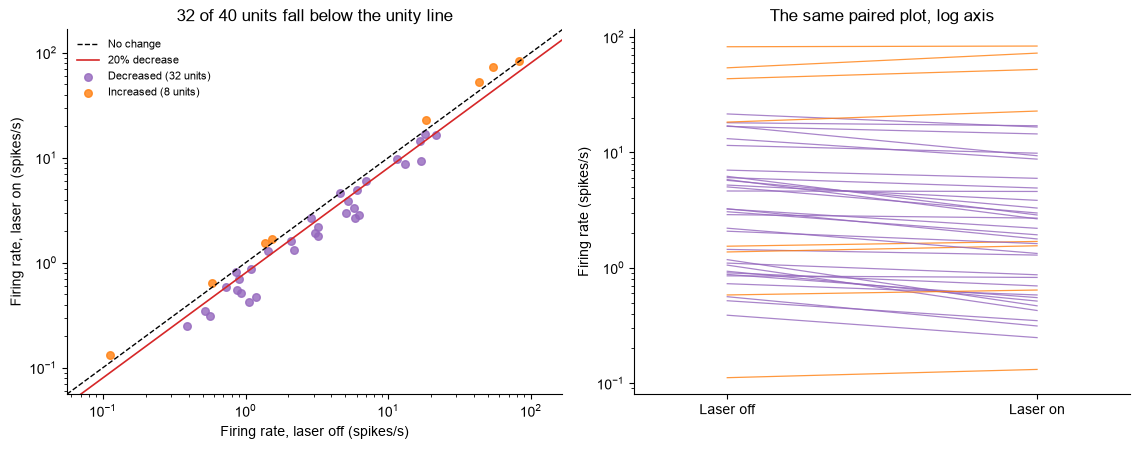

units that decreased : 32 of 40
median change        : -22.4%
geometric mean change: -24.4%
mean change in spikes/s (what the t-test tested): -0.295 (-3.2%)


In [3]:
below = on < off
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))

lims = [0.5*min(off.min(), on.min()), 2*max(off.max(), on.max())]
axes[0].plot(lims, lims, 'k--', lw=1.0, label='No change')
axes[0].plot(lims, [0.8*l for l in lims], '-', color='tab:red', lw=1.2,
             label='20% decrease')
axes[0].scatter(off[below], on[below], s=30, color='tab:purple', alpha=0.8,
                label=f'Decreased ({below.sum()} units)')
axes[0].scatter(off[~below], on[~below], s=30, color='tab:orange', alpha=0.8,
                label=f'Increased ({(~below).sum()} units)')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlim(*lims); axes[0].set_ylim(*lims)
axes[0].set_xlabel('Firing rate, laser off (spikes/s)')
axes[0].set_ylabel('Firing rate, laser on (spikes/s)')
axes[0].set_title(f'{below.sum()} of {n_units} units fall below the unity line')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')

for i in range(n_units):
    axes[1].plot([0, 1], [off[i], on[i]], '-',
                 color='tab:purple' if below[i] else 'tab:orange', lw=0.9, alpha=0.8)
axes[1].set_yscale('log')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Laser off', 'Laser on'])
axes[1].set_xlim(-0.3, 1.3)
axes[1].set_ylabel('Firing rate (spikes/s)')
axes[1].set_title('The same paired plot, log axis')
plt.tight_layout(); plt.show()

ratio = on / off
print(f'units that decreased : {below.sum()} of {n_units}')
print(f'median change        : {(np.median(ratio)-1)*100:+.1f}%')
print(f'geometric mean change: {(np.exp(np.mean(np.log(ratio)))-1)*100:+.1f}%')
print(f'mean change in spikes/s (what the t-test tested): '
      f'{(on-off).mean():+.3f} ({(on.mean()/off.mean()-1)*100:+.1f}%)')


## Evidence 2 — Three tests that find it, and one that does not

The Wilcoxon signed-rank test ranks the absolute differences and asks whether the
positive and negative ranks balance. The sign test throws away magnitude entirely
and just counts. The log-scale t-test turns the multiplicative effect into an
additive one, which is what a t-test is built for, and hands you an interpretable
effect size in the bargain.


In [4]:
diff = on - off
t_raw  = stats.ttest_rel(on, off)
w      = stats.wilcoxon(diff)
t_log  = stats.ttest_rel(np.log(on), np.log(off))
n_down = int(np.sum(diff < 0))
p_sign = stats.binomtest(n_down, n_units).pvalue

print(f'{"test":38s} {"statistic":>12s} {"p":>12s}')
print('-' * 64)
print(f'{"paired t on rate differences":38s} {t_raw.statistic:12.3f} {t_raw.pvalue:12.4f}')
print(f'{"Wilcoxon signed-rank":38s} {w.statistic:12.0f} {w.pvalue:12.6f}')
print(f'{"sign test (" + str(n_down) + " of 40 down)":38s} {n_down:12d} {p_sign:12.6f}')
print(f'{"paired t on LOG rates":38s} {t_log.statistic:12.3f} {t_log.pvalue:12.2e}')

lr = np.log(on/off)
ci = np.exp(np.mean(lr) + np.array([-1, 1])*stats.t.ppf(0.975, n_units-1)
            * np.std(lr, ddof=1)/np.sqrt(n_units))
print(f'\neffect size from the log scale: x{np.exp(np.mean(lr)):.3f} '
      f'(95% CI x{ci[0]:.3f} to x{ci[1]:.3f})')
print(f'  i.e. a {(1-np.exp(np.mean(lr)))*100:.0f}% reduction '
      f'({(1-ci[1])*100:.0f}% to {(1-ci[0])*100:.0f}%)')
print(f'  ground truth: the simulated factor had median 0.80, a 20% reduction')


test                                      statistic            p
----------------------------------------------------------------
paired t on rate differences                 -0.480       0.6340
Wilcoxon signed-rank                            163     0.000603
sign test (32 of 40 down)                        32     0.000182
paired t on LOG rates                        -5.633     1.67e-06

effect size from the log scale: x0.756 (95% CI x0.684 to x0.836)
  i.e. a 24% reduction (16% to 32%)
  ground truth: the simulated factor had median 0.80, a 20% reduction


## Evidence 3 — Why the paired t-test had no power

The effect is multiplicative, so the absolute change in spikes/s scales with the
unit's rate. The left panel shows that directly: a straight line of slope 1 on
log-log axes.

The consequence is on the right. The mean paired difference is a **rate-weighted**
average, so a few fast units carry most of it. The effective sample size for such
a weighted mean is `(sum r)^2 / sum(r^2)`, which here is about 10, not 40. The
same units also inflate the SD of the differences, so both the numerator and the
denominator of the t-statistic are being set by a handful of neurons.

Ranks do not care. Wilcoxon and the sign test give the 0.2 spikes/s unit exactly
as much say as the 16 spikes/s unit, which is appropriate when the effect you are
looking for is proportional.


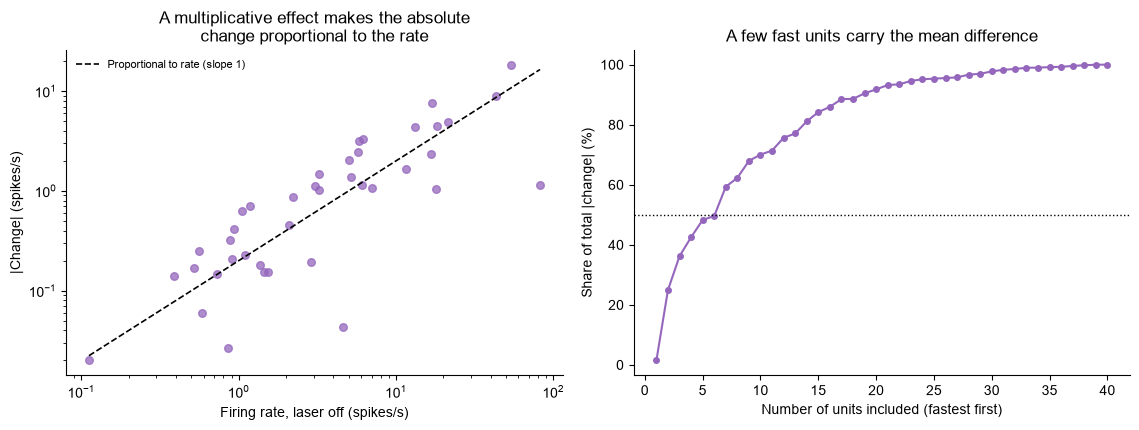

effective sample size of a rate-weighted mean: 10.0 of 40
  top  1 units by rate: 22.1% of total rate,  1.5% of total |change|
  top  3 units by rate: 48.2% of total rate, 36.2% of total |change|
  top  5 units by rate: 58.9% of total rate, 48.3% of total |change|
  top 10 units by rate: 79.5% of total rate, 70.0% of total |change|

mean difference -0.295 spikes/s, SD 3.888, SE 0.615
  -> t = -0.480
on the LOG scale: mean -0.280, SD 0.314, SE 0.050
  -> t = -5.633   <- same data, matched scale


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

axes[0].scatter(off, np.abs(diff), s=30, color='tab:purple', alpha=0.75)
xs = np.array([off.min(), off.max()])
axes[0].plot(xs, 0.2*xs, 'k--', lw=1.2, label='Proportional to rate (slope 1)')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Firing rate, laser off (spikes/s)')
axes[0].set_ylabel('|Change| (spikes/s)')
axes[0].set_title('A multiplicative effect makes the absolute\n'
                  'change proportional to the rate')
axes[0].legend(frameon=False, fontsize=8)

order = np.argsort(-off)
cum = np.cumsum(np.abs(diff)[order]) / np.abs(diff).sum()
axes[1].plot(np.arange(1, n_units+1), cum*100, 'o-', ms=4, color='tab:purple')
axes[1].axhline(50, color='k', ls=':', lw=1.0)
axes[1].set_xlabel('Number of units included (fastest first)')
axes[1].set_ylabel('Share of total |change| (%)')
axes[1].set_title('A few fast units carry the mean difference')
plt.tight_layout(); plt.show()

n_eff = (off.sum()**2) / (off**2).sum()
print(f'effective sample size of a rate-weighted mean: {n_eff:.1f} of {n_units}')
for k in (1, 3, 5, 10):
    print(f'  top {k:2d} units by rate: {off[order[:k]].sum()/off.sum()*100:4.1f}% of '
          f'total rate, {np.abs(diff)[order[:k]].sum()/np.abs(diff).sum()*100:4.1f}% '
          f'of total |change|')
print(f'\nmean difference {diff.mean():+.3f} spikes/s, SD {diff.std(ddof=1):.3f}, '
      f'SE {diff.std(ddof=1)/np.sqrt(n_units):.3f}')
print(f'  -> t = {diff.mean()/(diff.std(ddof=1)/np.sqrt(n_units)):+.3f}')
print(f'on the LOG scale: mean {np.mean(lr):+.3f}, SD {np.std(lr, ddof=1):.3f}, '
      f'SE {np.std(lr, ddof=1)/np.sqrt(n_units):.3f}')
print(f'  -> t = {np.mean(lr)/(np.std(lr, ddof=1)/np.sqrt(n_units)):+.3f}   '
      f'<- same data, matched scale')


## Evidence 4 — It is power, not calibration

Two simulations. First, the **strict null**: measure the same units twice with
nothing changing in between. Differences between exchangeable pairs are symmetric,
so the paired t-test is essentially exact here, and it is. The paired t-test is
not a badly calibrated test.

Second, the **real effect**: run this experiment 1500 times from the same
generative model and count how often each test finds the suppression that is
genuinely there.


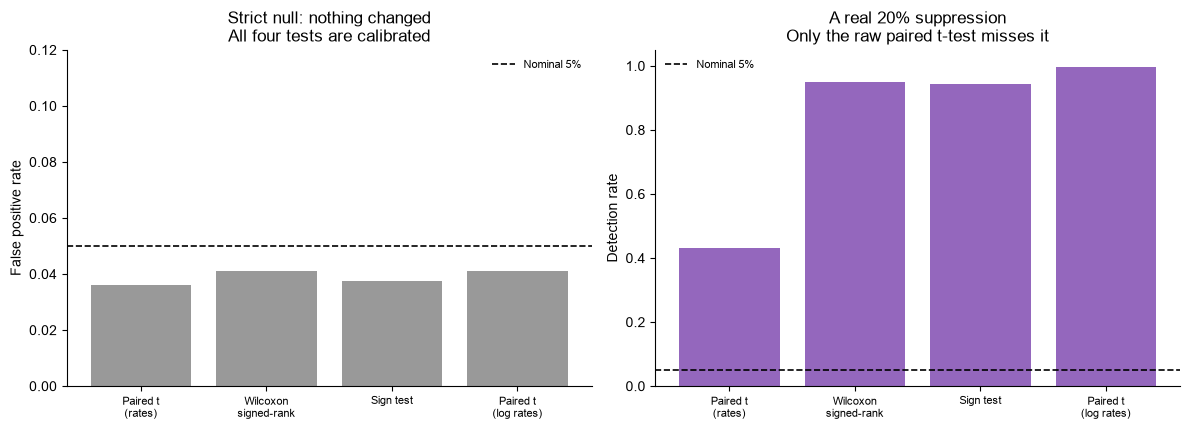

test                      Type I (no effect)  power (real 20% drop)
Paired t (rates)                       0.036                  0.430
Wilcoxon signed-rank                   0.041                  0.949
Sign test                              0.037                  0.942
Paired t (log rates)                   0.041                  0.997


In [6]:
def wilcoxon_p_fast(d):
    """Vectorized signed-rank p-value, normal approximation (fine at n = 40)."""
    n = d.shape[1]
    r = stats.rankdata(np.abs(d), axis=1)
    Wp = np.sum(r*(d > 0), axis=1)
    return 2*stats.norm.sf(np.abs(Wp - n*(n+1)/4.0)
                           / np.sqrt(n*(n+1)*(2*n+1)/24.0))

def experiment(rng, n_rep, factor_median):
    """factor_median = 1.0 gives the strict null (nothing changes)."""
    r0 = 4.0*np.exp(rng.normal(0, 1.7, (n_rep, n_units)))
    f  = factor_median*np.exp(rng.normal(0, 0.30, (n_rep, n_units))) \
         if factor_median != 1.0 else np.ones((n_rep, n_units))
    a = np.maximum(rng.poisson(r0*duration)/duration, 0.5/duration)
    b = np.maximum(rng.poisson(r0*f*duration)/duration, 0.5/duration)
    d = b - a
    k = np.sum(d > 0, axis=1)
    return {
        'Paired t\n(rates)':   np.mean(stats.ttest_rel(b, a, axis=1).pvalue < 0.05),
        'Wilcoxon\nsigned-rank': np.mean(wilcoxon_p_fast(d) < 0.05),
        'Sign test':            np.mean(2*np.minimum(
                                    stats.binom.cdf(k, n_units, 0.5),
                                    stats.binom.sf(k-1, n_units, 0.5)) < 0.05),
        'Paired t\n(log rates)': np.mean(stats.ttest_rel(np.log(b), np.log(a),
                                                        axis=1).pvalue < 0.05),
    }

rng = np.random.default_rng(7)
null_rates = experiment(rng, 4000, 1.0)
pow_rates  = experiment(rng, 1500, 0.80)

names = list(pow_rates)
x = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].bar(x, [null_rates[k] for k in names], color='0.6')
axes[0].axhline(0.05, color='k', ls='--', lw=1.2, label='Nominal 5%')
axes[0].set_ylim(0, 0.12); axes[0].set_ylabel('False positive rate')
axes[0].set_title('Strict null: nothing changed\nAll four tests are calibrated')
axes[1].bar(x, [pow_rates[k] for k in names], color='tab:purple')
axes[1].axhline(0.05, color='k', ls='--', lw=1.2, label='Nominal 5%')
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel('Detection rate')
axes[1].set_title('A real 20% suppression\nOnly the raw paired t-test misses it')
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=8)
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"test":24s} {"Type I (no effect)":>19s} {"power (real 20% drop)":>22s}')
for k in names:
    print(f'{k.replace(chr(10), " "):24s} {null_rates[k]:19.3f} {pow_rates[k]:22.3f}')


## Evidence 5 — Three tests, three different nulls

This is the part to remember, because "the t-test failed so use the
non-parametric one" is a habit worth not forming.

- The **paired t-test** tests `mean(difference) = 0`.
- The **Wilcoxon signed-rank test** tests that the differences are **symmetric
  about 0**. That is a stronger and different claim than a zero mean.
- The **sign test** tests `median(difference) = 0`.

When the differences are symmetric, all three nulls coincide and all three tests
are calibrated, which is the top two rows below. When the differences are skewed
they come apart, and each test rejects when its own null is false. Look at row
four: the mean difference is *exactly* zero, so the t-test is the only one whose
null is true, and Wilcoxon rejects 42% of the time and the sign test 66%.

That is not a bug in Wilcoxon. It is Wilcoxon correctly detecting asymmetry. But
if what you wanted was a statement about the mean, it did not give you one.

So the rule is not "use ranks." It is: **decide which summary answers your
question, then use the test for that summary, and if the effect is multiplicative
do the whole thing on a log scale** where the mean, the median and the symmetry
point all coincide again.


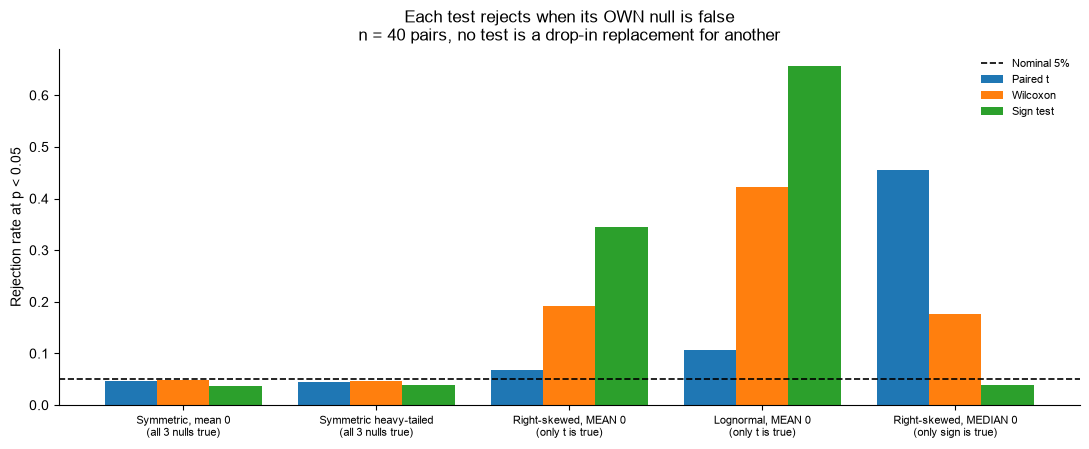

                 difference distribution  paired t  Wilcoxon    sign
    Symmetric, mean 0 (all 3 nulls true)     0.046     0.048   0.036
Symmetric heavy-tailed (all 3 nulls true)     0.045     0.047   0.039
   Right-skewed, MEAN 0 (only t is true)     0.067     0.191   0.345
      Lognormal, MEAN 0 (only t is true)     0.107     0.422   0.657
Right-skewed, MEDIAN 0 (only sign is true)     0.454     0.176   0.040

Direction of the paired-t error on right-skewed differences with mean 0:
  n =  10 pairs: 0.098 total, of which "decrease" 0.094 and "increase" 0.004
  n =  40 pairs: 0.067 total, of which "decrease" 0.058 and "increase" 0.009
  -> a one-sided paired t-test in the unlucky direction is badly inflated.


In [7]:
NR = 8000
rng = np.random.default_rng(11)
scenarios = [
    ('Symmetric, mean 0\n(all 3 nulls true)',       rng.normal(0, 1, (NR, n_units))),
    ('Symmetric heavy-tailed\n(all 3 nulls true)',  rng.standard_t(3, (NR, n_units))),
    ('Right-skewed, MEAN 0\n(only t is true)',
        rng.exponential(1.0, (NR, n_units)) - 1.0),
    ('Lognormal, MEAN 0\n(only t is true)',
        np.exp(rng.normal(0, 1.0, (NR, n_units))) - np.exp(0.5)),
    ('Right-skewed, MEDIAN 0\n(only sign is true)',
        rng.exponential(1.0, (NR, n_units)) - np.log(2)),
]

rows = []
for name, dd in scenarios:
    k = np.sum(dd > 0, axis=1)
    rows.append((name,
        np.mean(stats.ttest_1samp(dd, 0.0, axis=1).pvalue < 0.05),
        np.mean(wilcoxon_p_fast(dd) < 0.05),
        np.mean(2*np.minimum(stats.binom.cdf(k, n_units, 0.5),
                             stats.binom.sf(k-1, n_units, 0.5)) < 0.05)))

x = np.arange(len(rows)); w_ = 0.27
fig, ax = plt.subplots(figsize=(11, 4.6))
for j, (lab, c) in enumerate((('Paired t', 'tab:blue'),
                              ('Wilcoxon', 'tab:orange'),
                              ('Sign test', 'tab:green'))):
    ax.bar(x + (j-1)*w_, [r[j+1] for r in rows], w_, color=c, label=lab)
ax.axhline(0.05, color='k', ls='--', lw=1.2, label='Nominal 5%')
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows], fontsize=8)
ax.set_ylabel('Rejection rate at p < 0.05')
ax.set_title('Each test rejects when its OWN null is false\n'
             'n = 40 pairs, no test is a drop-in replacement for another')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"difference distribution":>40s} {"paired t":>9s} {"Wilcoxon":>9s} {"sign":>7s}')
for name, a_, b_, c_ in rows:
    print(f'{name.replace(chr(10), " "):>40s} {a_:9.3f} {b_:9.3f} {c_:7.3f}')

print('\nDirection of the paired-t error on right-skewed differences with mean 0:')
for nn in (10, 40):
    dd = rng.exponential(1.0, (20000, nn)) - 1.0
    r = stats.ttest_1samp(dd, 0.0, axis=1)
    lo = np.mean((r.pvalue < 0.05) & (r.statistic < 0))
    hi = np.mean((r.pvalue < 0.05) & (r.statistic > 0))
    print(f'  n = {nn:3d} pairs: {lo+hi:.3f} total, of which '
          f'"decrease" {lo:.3f} and "increase" {hi:.3f}')
print('  -> a one-sided paired t-test in the unlucky direction is badly inflated.')


## Ground truth


In [8]:
gt = np.load('data/ground_truth.npz', allow_pickle=True)
fac = gt['factor']
print(f'realized factors in this sample: median {np.median(fac):.3f}, '
      f'range {fac.min():.2f} to {fac.max():.2f}')
print(f'  (drawn around a POPULATION median of {float(gt["factor_median"]):.2f}, a {(1-float(gt["factor_median"]))*100:.0f}% decrease)')
print(f'units whose TRUE rate decreased: {int(np.sum(fac < 1))} of {n_units}')
print(f'true baseline rates: median {np.median(gt["rate_off"]):.2f}, '
      f'range {gt["rate_off"].min():.2f} to {gt["rate_off"].max():.1f} spikes/s')
print()
print(str(gt['note']))


realized factors in this sample: median 0.740, range 0.38 to 1.35
  (drawn around a POPULATION median of 0.80, a 20% decrease)
units whose TRUE rate decreased: 32 of 40
true baseline rates: median 3.17, range 0.12 to 81.5 spikes/s

The manipulation really does suppress firing: every unit's rate is multiplied by a factor with median 0.80, a 20% decrease. The paired t-test misses it because the effect is multiplicative while the test is applied to differences in spikes/s, which are proportional to rate. With lognormal rates that mean difference is a rate-weighted average with an effective sample size far below 40. This is a power failure, not a Type I failure.


## The lesson

- **A non-significant paired t-test is not evidence of no effect.** Here it
  returned p = 0.63 on a real 20% suppression that 32 of 40 units showed. The
  test was calibrated and honest; it simply had almost no power against this kind
  of effect.

- **Match the scale of the test to the shape of the effect.** Neural
  manipulations usually act multiplicatively, and firing rates are lognormal. A
  difference in spikes/s is then proportional to the baseline rate, so the mean
  difference is a rate-weighted average of a handful of fast units. Work in logs
  and the effect becomes additive, the differences become roughly normal, and the
  same t-test goes from p = 0.63 to p = 2e-06 on identical data.

- **Compute the effective sample size when you weight.** `(sum r)^2 / sum(r^2)`
  was 10 here, not 40. Any time your statistic implicitly weights observations by
  a heavy-tailed quantity, most of your sample is not participating.

- **Plot on the scale you are analyzing on, and look before you test.** One
  log-log scatter with a unity line showed the answer with no statistics at all.
  The linear-axis paired plot in the student notebook showed nothing, because 35
  of the 40 units were squashed into the bottom of it.

- **Rank tests are a different question, not a safer version of the same
  question.** The paired t-test, Wilcoxon and the sign test target the mean, the
  symmetry point and the median. They agree when the differences are symmetric and
  diverge sharply when they are not: with differences whose mean is exactly zero,
  Wilcoxon rejected 42% of the time and the sign test 66%. Choose the summary that
  answers your question first, then choose the test.

- **The one-sample and paired t-test have no protection against skew.** In a
  two-sample test with equal group sizes, the skew in the two sample means largely
  cancels. In a paired or one-sample test there is nothing to cancel against, so
  skewed differences hit the test directly and asymmetrically: on skewed
  differences with a true mean of zero, nearly all the false positives came out in
  one direction.
